In [1]:
# Chit 21: CIFAR-10 CNN: confusion matrix
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Step 2: Load and prepare CIFAR-10
data = pd.read_csv("cifar-10.csv", dtype=np.uint8)
y = data["label"].to_numpy(dtype="int64")
X = data.drop(columns="label").to_numpy(dtype="float32")
X = X.reshape(-1, 32, 32, 3) / 255.0

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
image_shape = (32, 32, 3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y
)

In [3]:
# Step 3: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=X_train.shape[1:]),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [4]:
# Step 4: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [5]:
# Step 5: Prepare and run the model
model.fit(X_train, y_train, epochs=10, batch_size=128, verbose=0)

In [6]:
# Step 6: Predict test images
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

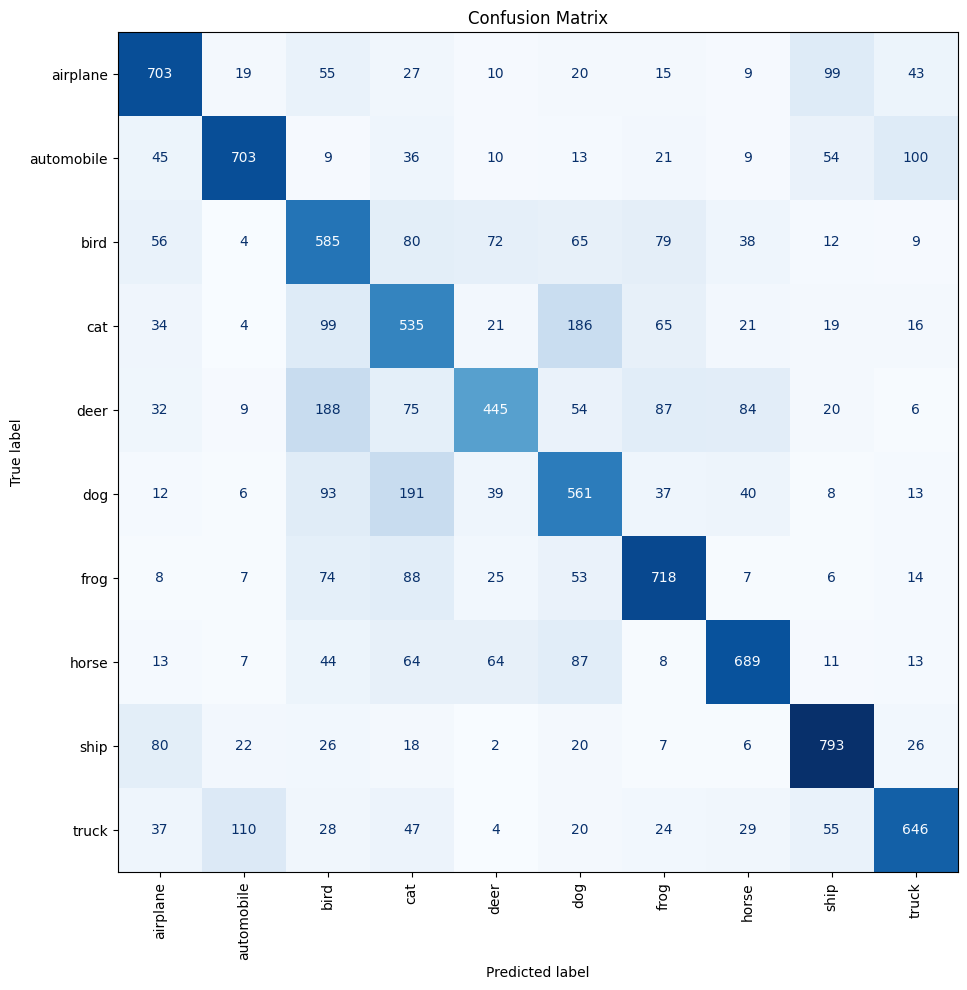

In [7]:
# Step 7: Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, xticks_rotation="vertical", colorbar=False, cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()